In [1]:
import os, sys, glob, zipfile

MARKER = os.path.join("src", "kmeans.py")      # a file that only this project has
EXTRACT_TO = "/content" if os.path.isdir("/content") else os.getcwd()

# 1. In Colab, connect Google Drive (a pop-up asks for permission)
try:
    from google.colab import drive
    if not os.path.isdir("/content/drive/MyDrive"):
        drive.mount("/content/drive")
except ImportError:
    pass  # not on Colab

def search_places():
    return [os.getcwd(), "/content", "/content/drive/MyDrive"]

def find_root():
    for base in search_places():
        if not os.path.isdir(base):
            continue
        if os.path.isfile(os.path.join(base, MARKER)):
            return base
        hits = glob.glob(os.path.join(base, "**", MARKER), recursive=True)
        if hits:
            return os.path.dirname(os.path.dirname(hits[0]))
    return None

def find_zips():
    zips = []
    for base in search_places():
        if os.path.isdir(base):
            zips += glob.glob(os.path.join(base, "**", "*kmeans*.zip"), recursive=True)
    return sorted(set(zips), key=os.path.getmtime, reverse=True)   # newest first

# 2. Use an unzipped copy in /content if there is one, otherwise unzip the newest zip
root = find_root() if os.path.isfile(os.path.join(EXTRACT_TO, "kmeanspp-project", MARKER)) else None
if root is None:
    zips = find_zips()
    if zips:
        print("Unzipping", zips[0])
        zipfile.ZipFile(zips[0]).extractall(EXTRACT_TO)
    root = find_root()

if root is None:
    raise FileNotFoundError(
        "Project not found. Put kmeanspp-project.zip in your Google Drive or the Colab file panel, "
        "allow Drive access when asked, then run this cell again.")

os.chdir(root)
if root not in sys.path:
    sys.path.insert(0, root)
print("Working in:", os.getcwd())
print(sorted(os.listdir(".")))

Mounted at /content/drive
Unzipping /content/drive/MyDrive/kmeanspp-project.zip
Working in: /content/kmeanspp-project
['.gitignore', 'README.md', 'report', 'requirements.txt', 'results', 'run_experiments.py', 'run_project.ipynb', 'src', 'tests']


In [2]:
%pip install -q numpy matplotlib scikit-learn pandas

In [3]:
import importlib
import tests.test_kmeans as t
importlib.reload(t)
for name in sorted(dir(t)):
    if name.startswith("test_"):
        getattr(t, name)()
        print("ok ", name)

ok  test_ari_matches_reference
ok  test_distances
ok  test_finds_obvious_clusters
ok  test_objective_never_increases
ok  test_seeding_picks_distinct_points


In [4]:
from src.datasets import norm_clusters
from src.kmeans import kmeans, adjusted_rand_index

X, y, _ = norm_clusters(seed=0)
for method in ["random", "kmeans++"]:
    r = kmeans(X, k=25, init=method, seed=0)
    print(f"{method:9s} final inertia = {r['inertia']:12.0f}   iterations = {r['n_iter']:2d}   ARI vs truth = {adjusted_rand_index(r['labels'], y):.3f}")

random    final inertia =    192867134   iterations = 14   ARI vs truth = 0.693
kmeans++  final inertia =        74656   iterations =  1   ARI vs truth = 1.000


In [5]:
%run run_experiments.py

Norm-25: X (5000, 15)
  k=10 done
  k=25 done
  k=50 done
Digits: X (1797, 64)
  k=10 done
  k=25 done
  k=50 done
  held-out: {'random': {'train_per_point': 658.3394162255407, 'test_per_point': 688.1383458833645, 'test_per_point_std': 13.914688556217499}, 'kmeans++': {'train_per_point': 656.3285651500098, 'test_per_point': 684.1429271671818, 'test_per_point_std': 13.384782109274388}}
All done in 103s


In [6]:
import pandas as pd
pd.read_csv("results/summary.csv")[["dataset","k","method","ratio_mean","ratio_max","cv_percent","hit_best_percent","iter_mean","pair_ari_mean","ari_truth_mean"]].round(3)

,dataset,k,method,ratio_mean,ratio_max,cv_percent,hit_best_percent,iter_mean,pair_ari_mean,ari_truth_mean
0,Norm-25,10,random,1.224,1.436,7.993,0.0,6.72,0.355,NaN
1,Norm-25,10,kmeans++,1.123,1.263,5.432,2.0,1.52,0.421,NaN
2,Norm-25,25,random,3181.805,5079.173,25.662,0.0,15.60,0.561,0.697
3,Norm-25,25,kmeans++,1.000,1.000,0.000,100.0,1.00,1.000,1.000
4,Norm-25,50,random,557.846,2036.614,96.333,0.0,19.98,0.586,NaN
5,Norm-25,50,kmeans++,1.003,1.007,0.174,12.0,18.84,0.640,NaN
6,Digits,10,random,1.020,1.090,2.249,24.0,20.08,0.753,0.618
7,Digits,10,kmeans++,1.019,1.088,2.172,12.0,18.98,0.751,0.610
8,Digits,25,random,1.023,1.059,1.070,0.0,22.60,0.643,NaN
9,Digits,25,kmeans++,1.020,1.057,1.112,2.0,20.30,0.655,NaN


norm25_box


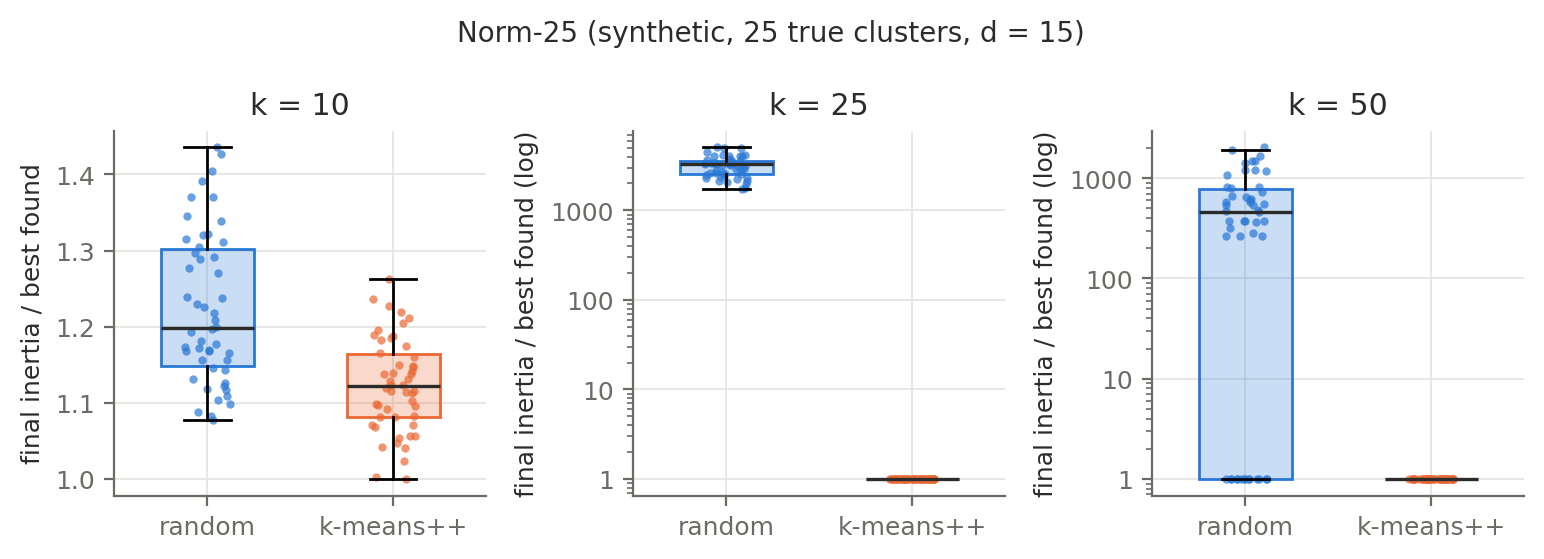

digits_box


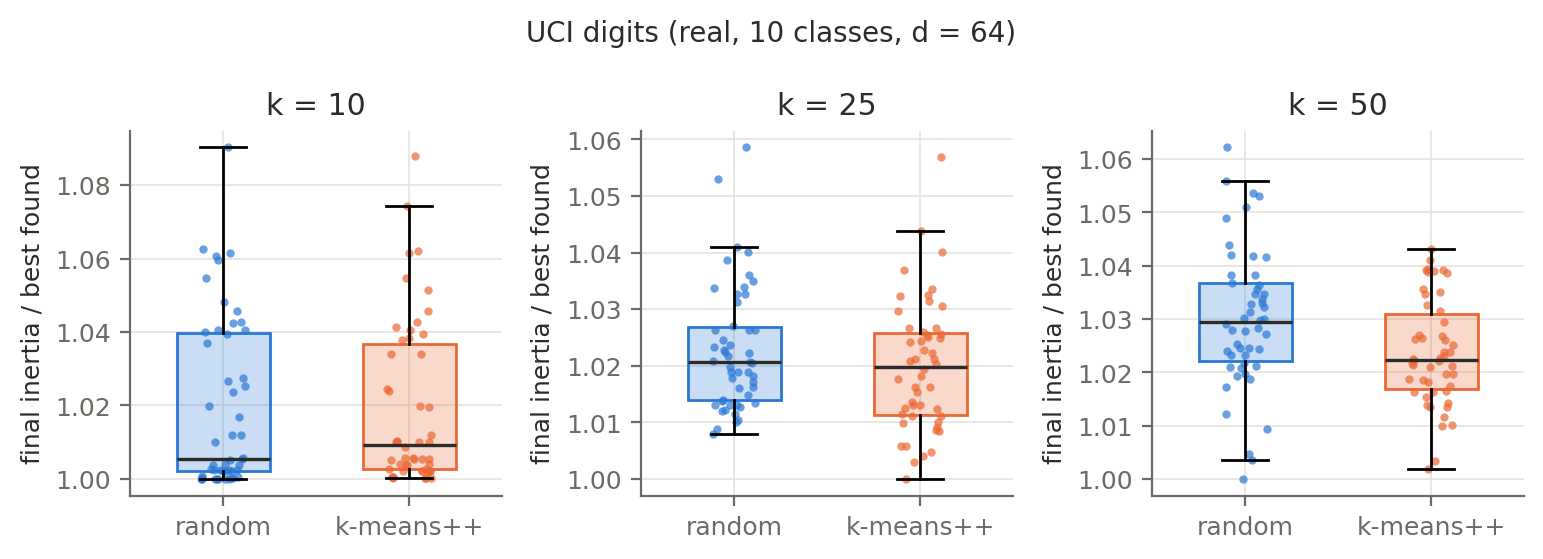

blobs2d_worst


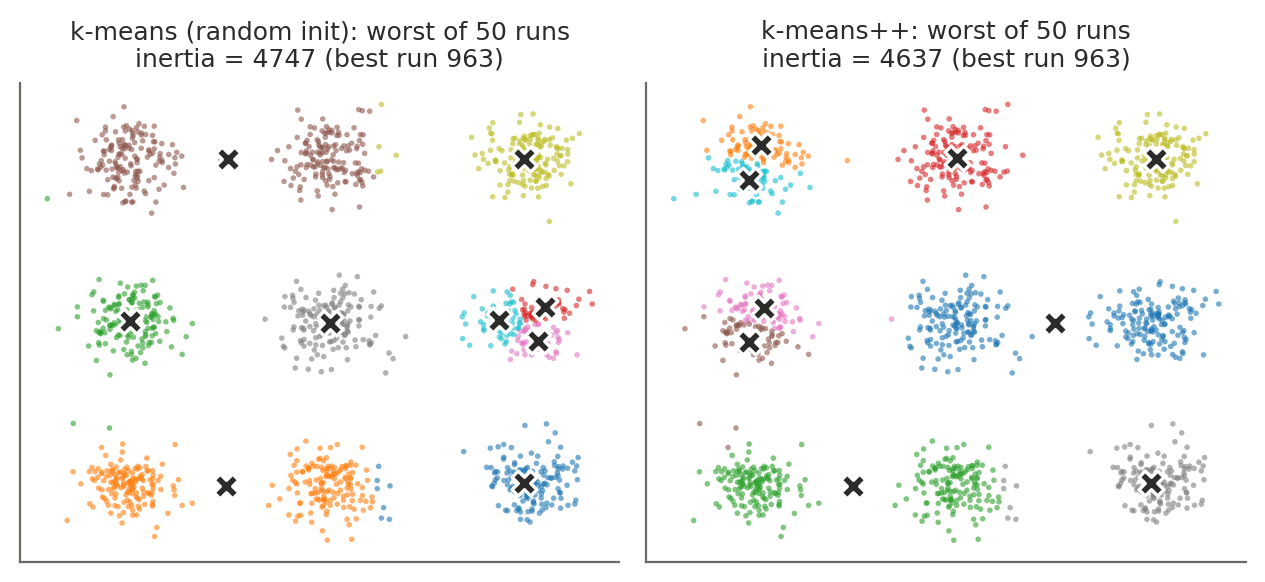

norm25_convergence


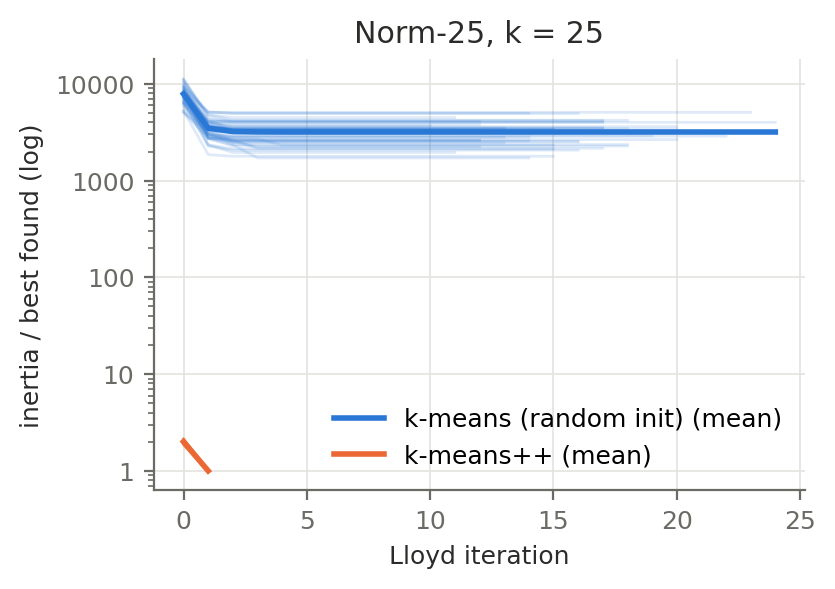

digits_convergence


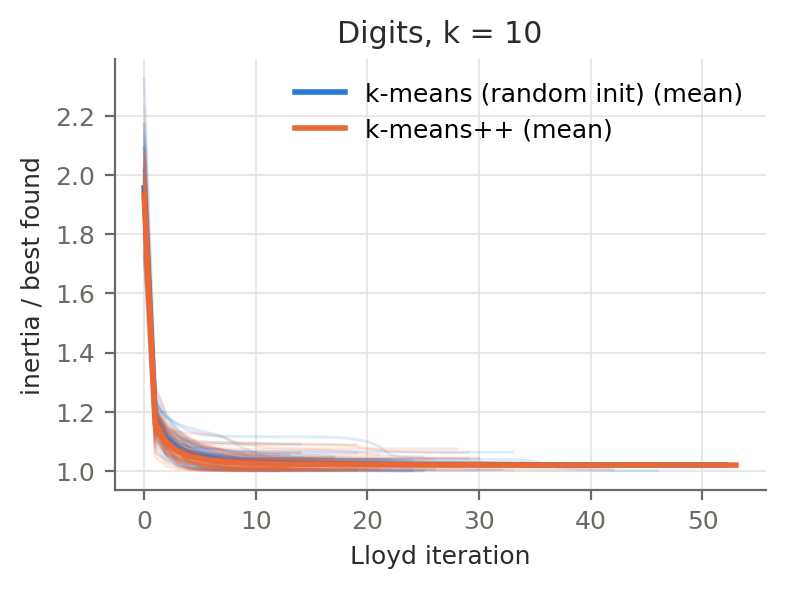

stability_pairwise_ari


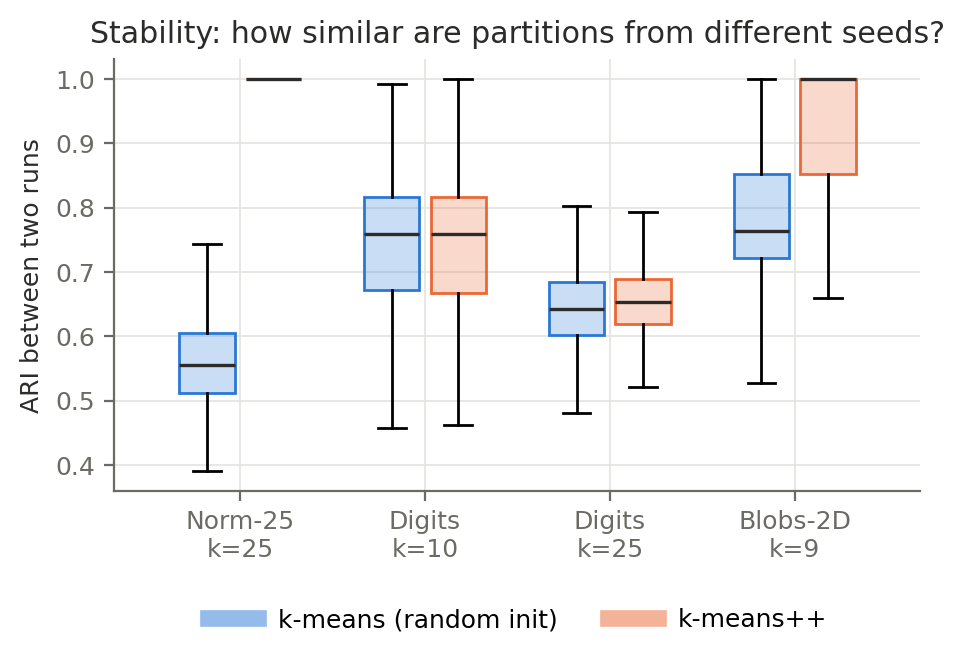

ext_overlap


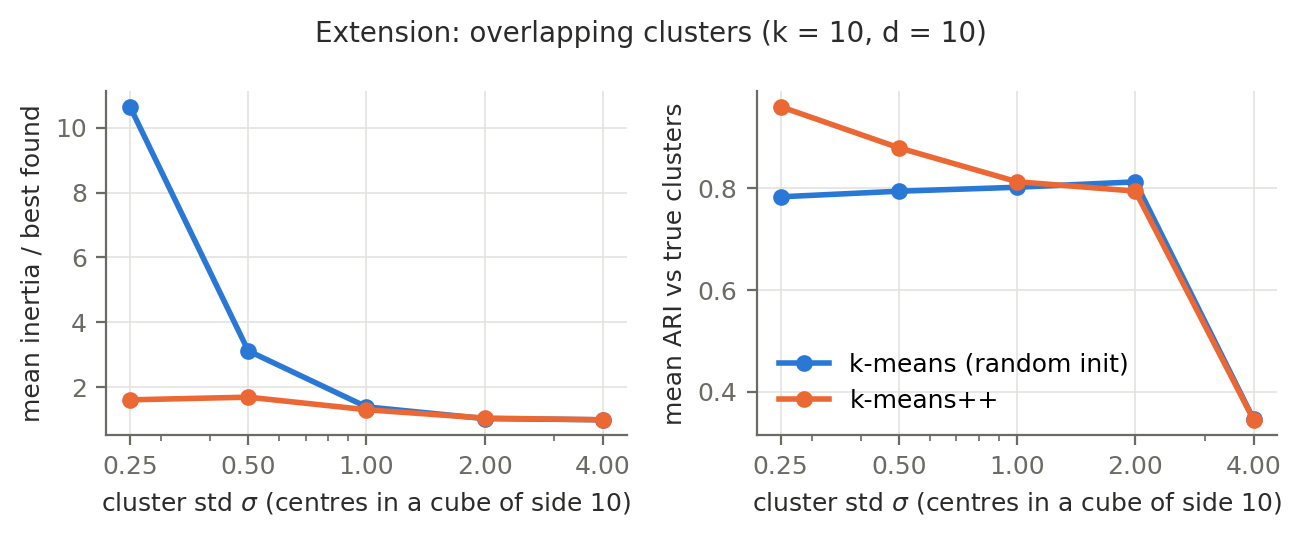

ext_dimension


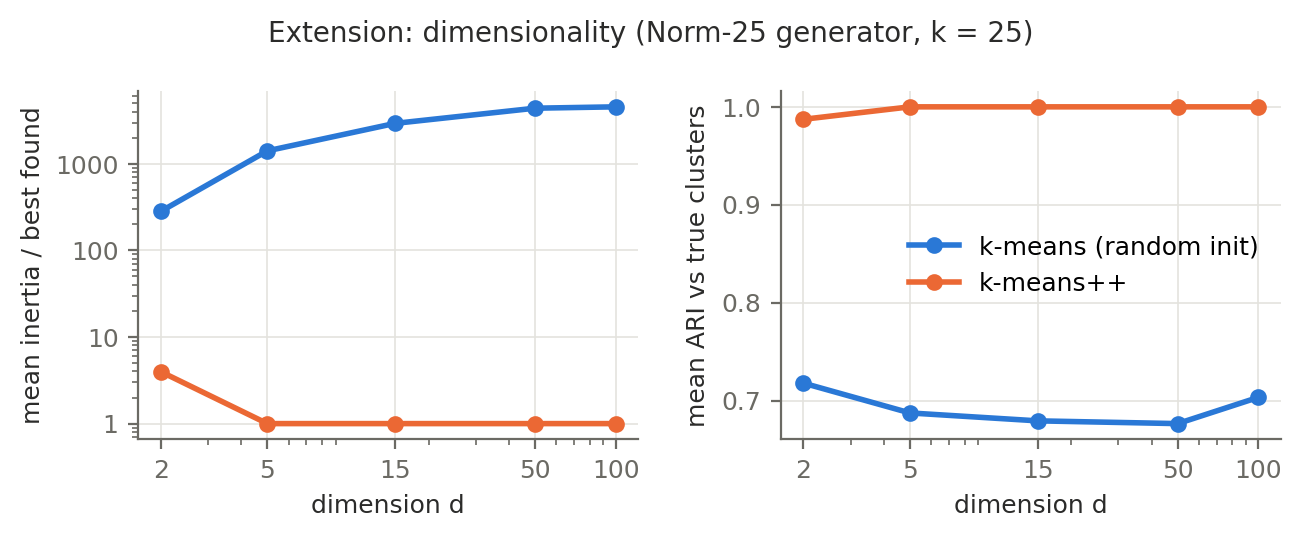

In [7]:
from IPython.display import Image, display
for name in ["norm25_box", "digits_box", "blobs2d_worst", "norm25_convergence",
             "digits_convergence", "stability_pairwise_ari", "ext_overlap", "ext_dimension"]:
    print(name)
    display(Image(filename=f"report/figures/{name}.png", width=750))